# 6. Comparación estadística e interpretabilidad

Sección 9.9.3 del curso: además de las métricas, se evalúa si las diferencias son significativas con
la prueba de **Diebold y Mariano (1995)** con la corrección de **Harvey, Leybourne y Newbold (1997)**,
se ajusta por comparaciones múltiples con **Bonferroni** (Demšar, 2006) y se estiman **intervalos de
confianza bootstrap** del RMSE (Efron, 1979). En P1 y P2 la pérdida es conjunta: la norma del vector de
errores estandarizados de las 4 salidas. La interpretabilidad usa **LIME** (sección 9.10.4.7).

In [1]:
import sys, warnings, json, time
from pathlib import Path
ML = Path.cwd().parent                      # carpeta ml/
sys.path.insert(0, str(ML))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
PROCESSED, REPORTS = ML / "data" / "processed", ML / "reports"
PRED = REPORTS / "predicciones"; PRED.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="deep")

In [2]:
# ===================== CONFIGURACIÓN =====================
ETAPA = "ajuste_fino"      # "base" o "ajuste_fino"
ALFA = 0.05
B_BOOTSTRAP = 1000

In [3]:
import itertools
from scipy import stats

def diebold_mariano(e1, e2, h=1):
    """H0: igual precisión. Pérdida cuadrática. Estadístico < 0 → el modelo 1 es más preciso."""
    e1, e2 = np.asarray(e1, float), np.asarray(e2, float); d = e1 ** 2 - e2 ** 2; T = len(d)
    if T < 5 or np.allclose(d, 0): return np.nan, np.nan
    dc = d - d.mean(); g = [dc @ dc / T] + [dc[k:] @ dc[:-k] / T for k in range(1, h)]
    var = max((g[0] + 2 * sum(g[1:])) / T, 1e-12)
    stat = d.mean() / np.sqrt(var) * np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)    # corrección HLN
    return stat, 2 * stats.t.sf(abs(stat), df=T - 1)

def matriz_dm(errores, h=1):
    pares = list(itertools.combinations(errores, 2)); m = len(pares); filas = []
    for a, b in pares:
        s, p = diebold_mariano(errores[a], errores[b], h)
        filas.append({"modelo_1": a, "modelo_2": b, "dm": s, "p": p, "p_bonferroni": min(p * m, 1) if np.isfinite(p) else np.nan,
                      "mejor": a if s < 0 else b})
    out = pd.DataFrame(filas); out["significativo"] = out["p_bonferroni"] < ALFA; return out

def bootstrap_rmse(e, B=B_BOOTSTRAP, bloque=1, semilla=42):
    e = np.asarray(e, float); n = len(e); rng = np.random.default_rng(semilla); v = []
    for _ in range(B):
        idx = (np.concatenate([np.arange(s, min(s + bloque, n)) for s in rng.integers(0, max(n - bloque, 1), int(np.ceil(n / bloque)))])[:n]
               if bloque > 1 else rng.integers(0, n, n))
        v.append(np.sqrt(np.mean(e[idx] ** 2)))
    return np.sqrt(np.mean(e ** 2)), *np.percentile(v, [2.5, 97.5])

def mapa(dm, titulo):
    n = sorted(set(dm.modelo_1) | set(dm.modelo_2)); M = pd.DataFrame(np.nan, index=n, columns=n)
    for r in dm.itertuples(): M.loc[r.modelo_1, r.modelo_2] = M.loc[r.modelo_2, r.modelo_1] = r.p_bonferroni
    plt.figure(figsize=(10, 8)); sns.heatmap(M, annot=True, fmt=".2f", cmap="viridis_r", vmin=0, vmax=0.1, cbar_kws={"label": "p ajustado (Bonferroni)"})
    plt.title(titulo); plt.show()

In [4]:
def comparar(problema):
    real = pd.read_parquet(PRED / f"{problema}_real.parquet").set_index("id")
    preds = {f.stem.replace(f"{problema}_{ETAPA}_", ""): pd.read_parquet(f).set_index("id").loc[real.index]
             for f in PRED.glob(f"{problema}_{ETAPA}_*.parquet")}
    esc = real.std()
    err = {m: np.sqrt((((real - P[real.columns]) / esc) ** 2).sum(axis=1)).to_numpy() for m, P in preds.items()}
    ic = pd.DataFrame({m: dict(zip(["RMSE_conjunto", "IC95_inf", "IC95_sup"], bootstrap_rmse(e))) for m, e in err.items()}).T.sort_values("RMSE_conjunto")
    return matriz_dm(err), ic

## 6.1 P1 · Kd por sector y tamaño

In [5]:
dm1, ic1 = comparar("p1"); ic1.round(3)

,RMSE_conjunto,IC95_inf,IC95_sup
XGBoost,1.194,1.103,1.282
Persistencia,1.318,1.201,1.436
Lasso,1.328,1.243,1.412
Random Forest,1.334,1.243,1.423
Gradient Boosting,1.375,1.287,1.456
Ridge,1.462,1.371,1.546
Regresión lineal,1.736,1.627,1.837
Árbol de decisión,1.746,1.633,1.850
SVR,1.766,1.650,1.882
k-NN,1.772,1.632,1.892


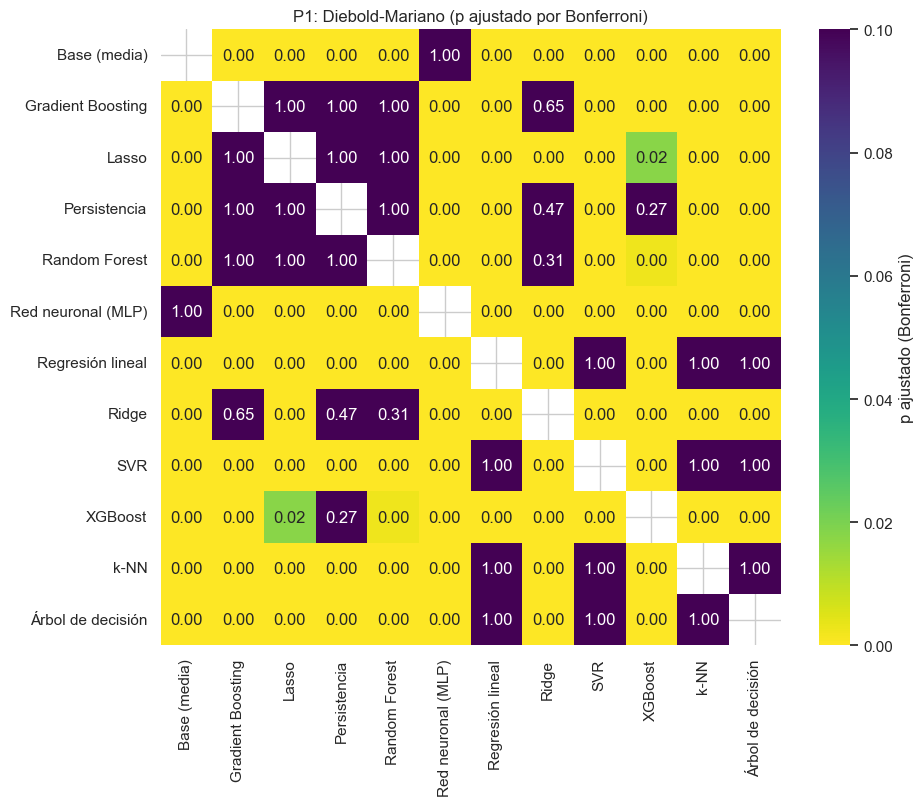

,modelo_1,modelo_2,dm,p_bonferroni,mejor
4,Base (media),Random Forest,11.715607,2.071518e-23,Random Forest
9,Base (media),XGBoost,11.684677,2.606115e-23,XGBoost
2,Base (media),Lasso,11.279141,5.211673e-22,Lasso
50,Random Forest,Árbol de decisión,-11.111631,1.781041e-21,Random Forest
33,Lasso,Regresión lineal,-10.998502,4.071856e-21,Lasso
3,Base (media),Persistencia,10.712817,3.248215e-20,Persistencia
0,Base (media),Gradient Boosting,10.605225,7.068372e-20,Gradient Boosting
34,Lasso,Ridge,-10.301187,6.270173e-19,Lasso
7,Base (media),Ridge,10.237562,9.872530e-19,Ridge
65,XGBoost,Árbol de decisión,-10.148754,1.857247e-18,XGBoost


In [6]:
mapa(dm1, "P1: Diebold-Mariano (p ajustado por Bonferroni)")
dm1[dm1.significativo].sort_values("p")[["modelo_1", "modelo_2", "dm", "p_bonferroni", "mejor"]].head(20)

## 6.2 P2 · Estructura de capital por empresa

In [7]:
dm2, ic2 = comparar("p2"); ic2.round(4)

,RMSE_conjunto,IC95_inf,IC95_sup
Random Forest,1.5109,1.4893,1.5323
XGBoost,1.5133,1.4917,1.5342
Gradient Boosting,1.5137,1.4919,1.5349
Árbol de decisión,1.5394,1.5169,1.5606
Red neuronal (MLP),1.5520,1.5224,1.5883
k-NN,1.5785,1.5569,1.5998
Ridge,1.6012,1.5592,1.6669
SVR,1.6013,1.5771,1.6248
Regresión lineal,1.6064,1.5645,1.6726
Persistencia,1.7194,1.6920,1.7465


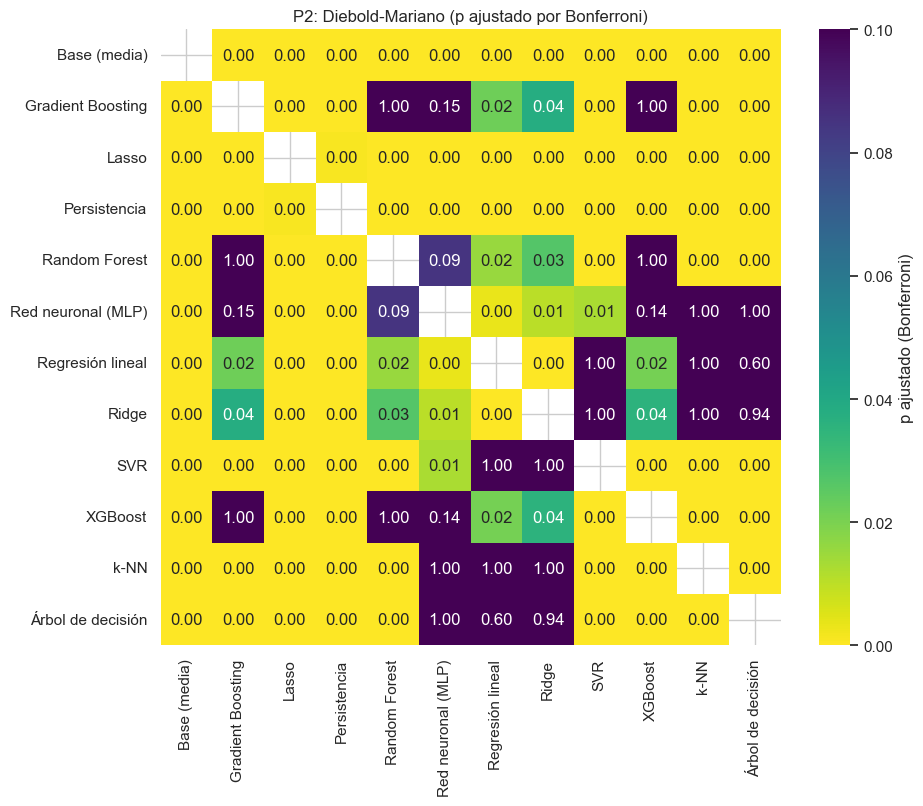

,modelo_1,modelo_2,dm,p_bonferroni,mejor
0,Base (media),Gradient Boosting,61.821183,0.000000e+00,Gradient Boosting
37,Lasso,Árbol de decisión,46.721207,0.000000e+00,Árbol de decisión
36,Lasso,XGBoost,47.465103,0.000000e+00,XGBoost
35,Lasso,SVR,42.686351,0.000000e+00,SVR
21,k-NN,Lasso,-39.244456,0.000000e+00,k-NN
12,Gradient Boosting,Lasso,-47.727427,0.000000e+00,Gradient Boosting
10,Base (media),Árbol de decisión,61.528197,0.000000e+00,Árbol de decisión
9,Base (media),XGBoost,61.582956,0.000000e+00,XGBoost
31,Lasso,Random Forest,44.679256,0.000000e+00,Random Forest
2,Base (media),Lasso,49.346635,0.000000e+00,Lasso


In [8]:
mapa(dm2, "P2: Diebold-Mariano (p ajustado por Bonferroni)")
dm2[dm2.significativo].sort_values("p")[["modelo_1", "modelo_2", "dm", "p_bonferroni", "mejor"]].head(20)

## 6.3 P3 · Insumos de mercado: ¿algún modelo le gana al paseo aleatorio?

In [9]:
P3 = pd.read_parquet(PROCESSED / "dataset_p3.parquet")
OBJ3 = ["spread_soberano", "tes_cop_10a", "tes_uvr_10a", "inflacion_implicita_10a", "tasa_politica", "ust_10a"]
filas = []
for h in (1, 3, 6, 12):
    preds = {f.stem.split(f"_h{h}_")[1]: pd.read_parquet(f) for f in PRED.glob(f"p3_{ETAPA}_h{h}_*.parquet")}
    if not preds: continue
    comun = sorted(set.intersection(*[set(P.index) for P in preds.values()])); real = P3.loc[comun, OBJ3]; esc = P3[OBJ3].diff().std()
    err = {m: np.sqrt((((real - P.loc[comun, OBJ3]) / esc) ** 2).sum(axis=1)).to_numpy() for m, P in preds.items()}
    for m, e in err.items():
        if m == "Paseo aleatorio": continue
        s, p = diebold_mariano(e, err["Paseo aleatorio"], h)
        r, lo, hi = bootstrap_rmse(e, bloque=3)
        filas.append({"h": h, "modelo": m, "RMSE_conjunto": r, "IC95": f"[{lo:.2f}, {hi:.2f}]",
                      "RMSE_paseo_aleatorio": bootstrap_rmse(err["Paseo aleatorio"], B=1)[0], "dm": s, "p_bonferroni": min(p * (len(err) - 1), 1),
                      "gana_al_paseo": (s < 0) and (p * (len(err) - 1) < ALFA)})
pd.DataFrame(filas).round(3)

,h,modelo,RMSE_conjunto,IC95,RMSE_paseo_aleatorio,dm,p_bonferroni,gana_al_paseo
0,1,ARIMA,2.532,"[2.05, 2.84]",2.541,-0.331,1.000,False
1,1,Prophet,7.303,"[5.41, 8.52]",2.541,6.931,0.000,False
2,1,Random Forest,4.112,"[2.83, 5.10]",2.541,2.858,0.043,False
3,1,Ridge,2.877,"[2.48, 3.21]",2.541,2.559,0.090,False
4,1,VAR,2.955,"[2.36, 3.45]",2.541,2.933,0.035,False
5,1,XGBoost,3.483,"[2.65, 4.16]",2.541,3.133,0.021,False
6,3,ARIMA,4.281,"[3.62, 4.83]",4.330,-0.377,1.000,False
7,3,Prophet,9.883,"[7.37, 11.70]",4.330,3.203,0.017,False
8,3,Random Forest,6.964,"[5.19, 8.74]",4.330,2.174,0.219,False
9,3,Ridge,5.197,"[4.56, 5.90]",4.330,1.917,0.381,False


## 6.4 Interpretabilidad con LIME

In [10]:
from lime.lime_tabular import LimeTabularExplainer
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from mirage.ml import gpu as G

def explicar(problema, estimador, objetivo, fila=0, n_variables=8):
    d = pd.read_parquet(PROCESSED / f"dataset_{problema}.parquet").merge(pd.read_parquet(PROCESSED / f"particion_{problema}.parquet"), on="id")
    if problema == "p1":
        Y = d[[c for c in d.columns if c.startswith("y_")]]; X = d.drop(columns=list(Y.columns) + ["split", "id", "mes"])
    else:
        Y = d[["y_de", "y_cob", "y_kd", "y_roa"]]
        X = d[["ciiu_division", "log_activos", "de", "de_l1", "cob", "kd", "roa", "roa_l1", "margen", "caja_activos", "deuda_activos", "crec_deuda", "tasa_impuesto_efectiva", "tasa_politica", "tes_10a_banrep", "ust_10a"]]
    tr = (d.split == "train").to_numpy(); num = [c for c in X.columns if c != "ciiu_division"]
    prep = ColumnTransformer([("num", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), num),
                              ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")), ("o", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False))]), ["ciiu_division"])])
    Xt = prep.fit_transform(X[tr]); m = clone(estimador).fit(Xt, Y[tr].to_numpy()); j = list(Y.columns).index(objetivo)
    exp = LimeTabularExplainer(Xt, feature_names=list(prep.get_feature_names_out()), mode="regression", random_state=42)
    e = exp.explain_instance(prep.transform(X[~tr].iloc[[fila]])[0], lambda z: np.asarray(m.predict(z)).reshape(len(z), -1)[:, j], num_features=n_variables)
    print(f"{problema} · objetivo {objetivo} · observación {d.loc[~tr, 'id'].iloc[fila]} · predicción {e.predicted_value:.3f}")
    return pd.DataFrame(e.as_list(), columns=["condición", "aporte"])

explicar("p1", G.xgb_boost(n_estimators=300, max_depth=6, learning_rate=0.1), "y_tasa_gran")

p1 · objetivo y_tasa_gran · observación 01_2025-07 · predicción 13.182


,condición,aporte
0,num__tasa_gran_l0 <= -0.67,-2.256291
1,num__tasa_gran_l1 <= -0.62,-1.821817
2,cat__ciiu_division_70 <= 0.00,0.993148
3,num__tasa_gran_l2 <= -0.58,-0.509057
4,num__tasa_pequeña_l0 <= -0.65,-0.493074
5,cat__ciiu_division_45 <= 0.00,-0.406418
6,num__tasa_microempresa_l1 <= -0.41,-0.393142
7,num__tasa_microempresa_l0 <= -0.46,-0.267024


In [11]:
explicar("p2", G.xgb_boost(n_estimators=300, max_depth=6, learning_rate=0.1), "y_kd")

p2 · objetivo y_kd · observación 890926766_2024 · predicción 0.353


,condición,aporte
0,num__kd > 0.36,0.109697
1,cat__ciiu_division_92 <= 0.00,-0.092632
2,cat__ciiu_division_03 <= 0.00,-0.060466
3,num__tes_10a_banrep > 0.09,0.037808
4,cat__ciiu_division_09 <= 0.00,-0.037000
5,cat__ciiu_division_31 <= 0.00,-0.031668
6,cat__ciiu_division_53 <= 0.00,0.030506
7,cat__ciiu_division_50 <= 0.00,0.015743


## 6.5 Elección del modelo final

Criterios sugeridos para elegir, por problema:
1. Que el modelo supere a la **persistencia** (P1, P2) o al **paseo aleatorio** (P3) con diferencia
   significativa tras Bonferroni; si ninguno lo hace, la línea base es el modelo a publicar.
2. Entre los que la superan, el de menor RMSE conjunto con intervalo bootstrap que no se traslape.
3. Brecha entrenamiento–prueba aceptable (notebooks 4 y 5).
4. Interpretabilidad (LIME) coherente con la teoría financiera.